# EDA & Data Cleaning Practice

This notebook walks through exploring and cleaning `messy_customer_data.csv` - a small synthetic dataset with duplicates, missing values, inconsistent text, and outliers baked in on purpose.

Cells marked **`# TODO`** are for you to fill in - try them yourself before checking the hints in the markdown above each one.

**Libraries used:** `pandas`, `matplotlib`, `seaborn`

## 1. Setup & Load Data

In [1]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import warnings 
warnings.filterwarnings('ignore')

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

file_path = '/content/drive/MyDrive/datasets/messy_customer_data.csv'
df = pd.read_csv(file_path)
df.head()

,customer_id,name,country,age,annual_income,signup_year,num_purchases,satisfaction_score
0,1,Hassan Ali,germany,52.0,62371.07,2019,0,1.0
1,2,Elena Petrova,canada,31.0,58356.82,2019,4,2.0
2,3,Alice Johnson,usa,65.0,30560.46,2022,3,3.0
3,4,Bob Smith,India,18.0,60114.83,2021,7,3.0
4,5,Elena Petrova,NaN,51.0,47839.27,2019,6,3.0


## 2. First Look: Shape, Types, and Summary Stats

In [13]:
print("Shape:", df.shape)
df.info()

Shape: (126, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         126 non-null    int64  
 1   name                126 non-null    object 
 2   country             117 non-null    object 
 3   age                 119 non-null    float64
 4   annual_income       117 non-null    float64
 5   signup_year         126 non-null    int64  
 6   num_purchases       126 non-null    int64  
 7   satisfaction_score  117 non-null    float64
dtypes: float64(3), int64(3), object(2)
memory usage: 8.0+ KB


In [14]:
df.describe(include="all")

,customer_id,name,country,age,annual_income,signup_year,num_purchases,satisfaction_score
count,126.000000,126,117,119.000000,117.000000,126.000000,126.000000,117.000000
unique,NaN,10,15,NaN,NaN,NaN,NaN,NaN
top,NaN,Ingrid Novak,canada,NaN,NaN,NaN,NaN,NaN
freq,NaN,15,14,NaN,NaN,NaN,NaN,NaN
mean,63.500000,NaN,NaN,40.000000,62732.594274,2020.952381,4.015873,2.897436
std,36.517119,NaN,NaN,14.060402,59306.338825,1.479768,2.101368,1.452611
min,1.000000,NaN,NaN,5.000000,19906.100000,2019.000000,0.000000,1.000000
25%,32.250000,NaN,NaN,32.000000,45694.540000,2020.000000,3.000000,1.000000
50%,63.500000,NaN,NaN,40.000000,54257.810000,2021.000000,4.000000,3.000000
75%,94.750000,NaN,NaN,47.500000,64569.290000,2022.000000,5.000000,4.000000


**TODO:** Just from `.info()` and `.describe()`, jot down (in a markdown cell or comments) which columns look like they have missing values, and which numeric columns look like they might have outliers based on `min`/`max` vs the mean.

<details>

**Observations:**
- `country`, `age`, `annual_income`, and `satisfaction_score` all have fewer non-null entries than `customer_id` - they contain missing values.
- `age` has a max of 97 and a min of 5, both far from the mean (~38) - likely outliers.
- `annual_income` has a max in the hundreds of thousands while the mean is ~$55K - a couple of extreme high values are pulling the max up.

</details>

In [ ]:
# Get the total count of NA values for each column
df.isna().sum()

,0
customer_id,0
name,0
country,9
age,7
annual_income,9
signup_year,0
num_purchases,0
satisfaction_score,9


## 3. Duplicate Rows
Duplicates can hide as exact row copies. Use `.duplicated()` to find them.

In [16]:
print("Number of exact duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values('name')

Number of exact duplicate rows: 0


,customer_id,name,country,age,annual_income,signup_year,num_purchases,satisfaction_score


**TODO:** Drop the duplicate rows (keep the first occurrence of each) and confirm the new shape.

In [ ]:
# TODO: drop duplicates and store in a new dataframe, e.g. df_dedup
df_dedup = None  # replace None
# df_dedup.shape

<details>

```python
df_dedup = df.drop_duplicates().reset_index(drop=True)
print("Original shape:", df.shape)
print("After dropping duplicates:", df_dedup.shape)
```

</details>

In [19]:
df_dedup = df.drop_duplicates().reset_index(drop=True)
print("Original shape:", df.shape)
print("After dropping duplicates:", df_dedup.shape)

Original shape: (126, 8)
After dropping duplicates: (126, 8)


## 4. Missing Data
Count missing values per column, then visualize *where* they occur.

In [20]:
df_dedup = df.drop_duplicates().reset_index(drop=True)  # safety net if step 3 wasn't finished
missing_counts = df_dedup.isna().sum()
missing_pct = (missing_counts / len(df_dedup) * 100).round(1)
pd.DataFrame({"missing_count": missing_counts, "missing_pct": missing_pct})

,missing_count,missing_pct
customer_id,0,0.0
name,0,0.0
country,9,7.1
age,7,5.6
annual_income,9,7.1
signup_year,0,0.0
num_purchases,0,0.0
satisfaction_score,9,7.1


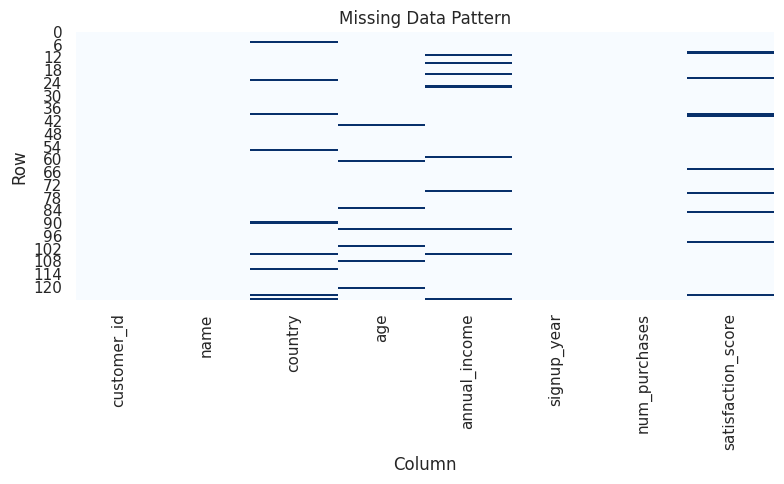

In [21]:
plt.figure(figsize=(8, 5))
sns.heatmap(df_dedup.isna(), cbar=False, cmap="Blues")
plt.title("Missing Data Pattern")
plt.xlabel("Column")
plt.ylabel("Row")
plt.tight_layout()
plt.show()

**TODO:** Pick one policy per column and apply it:
- `country` (categorical) → try **masking** (fill with `"Unknown"`) or **removing** those rows
- `age` (numeric) → try **imputing** with the median
- `annual_income` (numeric) → try **imputing** with the median (think about why median might beat mean here)
- `satisfaction_score` (numeric, small integer scale) → try **imputing** with the mode

Write your reasoning for each choice in a comment.

In [ ]:
# TODO: handle missing values, e.g.
# df_clean = df_dedup.copy()
# df_clean["country"] = df_clean["country"].fillna("Unknown")
# df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
# df_clean["annual_income"] = df_clean["annual_income"].fillna(df_clean["annual_income"].median())
# df_clean["satisfaction_score"] = df_clean["satisfaction_score"].fillna(df_clean["satisfaction_score"].mode()[0])

df_clean = df_dedup.copy()

<details>

```python
df_clean = df_dedup.copy()

df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["annual_income"] = df_clean["annual_income"].fillna(df_clean["annual_income"].median())
df_clean["satisfaction_score"] = df_clean["satisfaction_score"].fillna(df_clean["satisfaction_score"].mode()[0])

df_clean.isna().sum()
```

</details>

In [22]:
df_clean = df_dedup.copy()

df_clean["country"] = df_clean["country"].fillna("Unknown")
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["annual_income"] = df_clean["annual_income"].fillna(df_clean["annual_income"].median())
df_clean["satisfaction_score"] = df_clean["satisfaction_score"].fillna(df_clean["satisfaction_score"].mode()[0])

df_clean.isna().sum()

,0
customer_id,0
name,0
country,0
age,0
annual_income,0
signup_year,0
num_purchases,0
satisfaction_score,0


## 5. Inconsistent Text
The `country` column has inconsistent casing and stray whitespace (e.g. `"USA"`, `"usa "`, `"U.S.A."`).

In [23]:
df_clean["country"].value_counts(dropna=False)

,count
country,
canada,14
Germany,13
germany,11
India,10
U.S.A.,10
UK,9
Unknown,9
INDIA,8
United States,7


**TODO:** Standardize `country` values. Steps to try:
1. Strip whitespace and lowercase everything for comparison.
2. Map known variants (e.g. `"u.s.a."`, `"usa"` → `"USA"`) to one clean label.
3. Re-check `.value_counts()` afterward to confirm it collapsed correctly.

In [ ]:
# TODO: clean up the country column
country_map = {
    # "usa": "USA", "u.s.a.": "USA", ...
}

# df_clean["country"] = (
#     df_clean["country"]
#     .str.strip()
#     .str.lower()
#     .map(country_map)
#     .fillna(df_clean["country"])
# )

<details>

```python
country_map = {
    "usa": "USA",
    "u.s.a.": "USA",
    "united states": "USA",
    "canada": "Canada",
    "uk": "UK",
    "u.k.": "UK",
    "united kingdom": "UK",
    "germany": "Germany",
    "india": "India",
    "unknown": "Unknown",
}

df_clean["country"] = (
    df_clean["country"]
    .str.strip()
    .str.lower()
    .map(country_map)
    .fillna(df_clean["country"])
)

df_clean["country"].value_counts(dropna=False)

```

</details>

In [24]:
country_map = {
    "usa": "USA",
    "u.s.a.": "USA",
    "united states": "USA",
    "canada": "Canada",
    "uk": "UK",
    "u.k.": "UK",
    "united kingdom": "UK",
    "germany": "Germany",
    "india": "India",
    "unknown": "Unknown",
}

df_clean["country"] = (
    df_clean["country"]
    .str.strip()
    .str.lower()
    .map(country_map)
    .fillna(df_clean["country"])
)

df_clean["country"].value_counts(dropna=False)

,count
country,
USA,29
Germany,24
India,23
UK,22
Canada,19
Unknown,9


## 6. Finding Outliers

### 6a. Visual inspection

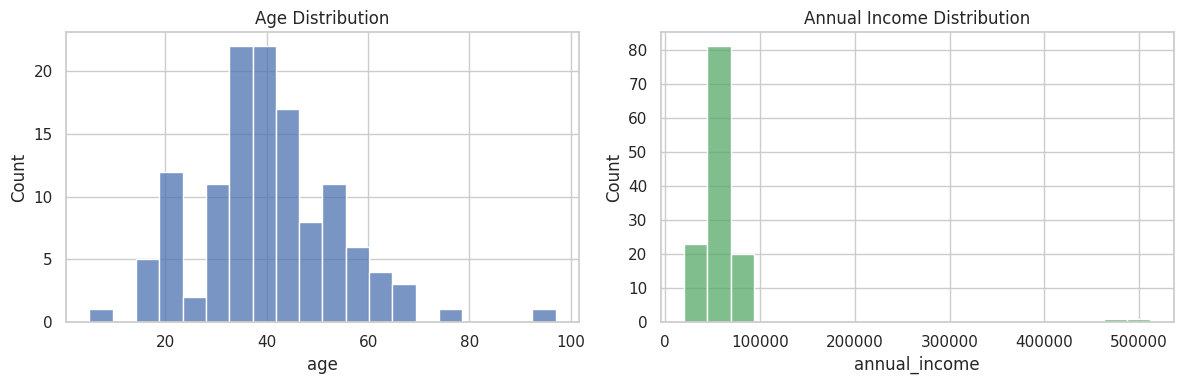

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_clean["age"], bins=20, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age Distribution")

sns.histplot(df_clean["annual_income"], bins=20, ax=axes[1], color="#55A868")
axes[1].set_title("Annual Income Distribution")

plt.tight_layout()
plt.show()

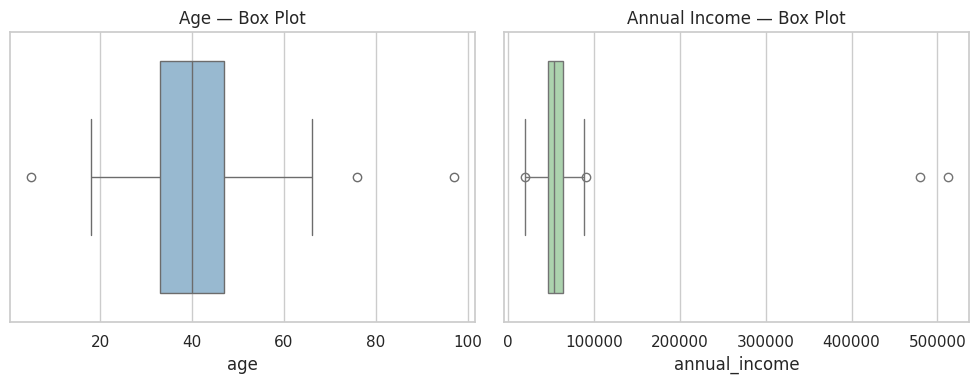

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x=df_clean["age"], ax=axes[0], color="#8FBBD9")
axes[0].set_title("Age - Box Plot")

sns.boxplot(x=df_clean["annual_income"], ax=axes[1], color="#A6D8A8")
axes[1].set_title("Annual Income - Box Plot")

plt.tight_layout()
plt.show()

### 6b. Statistical method: the 1.5×IQR rule

**TODO:** Write a function `flag_outliers_iqr(series)` that:
1. Computes Q1 (25th percentile) and Q3 (75th percentile)
2. Computes `IQR = Q3 - Q1`
3. Returns a boolean mask that's `True` for any value below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`

Then apply it to `age` and `annual_income` and print how many outliers each has.

In [ ]:
def flag_outliers_iqr(series):
    # TODO: implement the 1.5xIQR rule
    q1 = None
    q3 = None
    iqr = None
    lower_bound = None
    upper_bound = None
    return None  # replace with the boolean mask

# age_outliers = flag_outliers_iqr(df_clean["age"])
# income_outliers = flag_outliers_iqr(df_clean["annual_income"])
# print("Age outliers:", age_outliers.sum())
# print("Income outliers:", income_outliers.sum())

<details>

```python
def flag_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return (series < lower_bound) | (series > upper_bound)

age_outliers = flag_outliers_iqr(df_clean["age"])
income_outliers = flag_outliers_iqr(df_clean["annual_income"])
print("Age outliers:", age_outliers.sum())
print("Income outliers:", income_outliers.sum())
```

</details>

In [27]:
def flag_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return (series < lower_bound) | (series > upper_bound)

age_outliers = flag_outliers_iqr(df_clean["age"])
income_outliers = flag_outliers_iqr(df_clean["annual_income"])
print("Age outliers:", age_outliers.sum())
print("Income outliers:", income_outliers.sum())

Age outliers: 3
Income outliers: 4


**TODO:** Look at the flagged rows directly. Do any of them look like genuine data errors (e.g., an implausible age) versus values that might be real (e.g., a legitimately high earner)?

In [29]:
# TODO: inspect flagged rows, e.g.
# df_clean[age_outliers]
# df_clean[income_outliers]

In [31]:
df_clean[age_outliers]

,customer_id,name,country,age,annual_income,signup_year,num_purchases,satisfaction_score
35,36,Ingrid Novak,UK,97.0,36258.34,2023,3,1.0
56,57,Grace Kim,Germany,5.0,53428.82,2023,1,1.0
73,74,Jamal Brown,UK,76.0,56262.45,2023,1,2.0


In [30]:
df_clean[income_outliers]

,customer_id,name,country,age,annual_income,signup_year,num_purchases,satisfaction_score
13,14,Ingrid Novak,USA,46.0,19906.10,2023,5,4.0
48,49,Elena Petrova,Germany,63.0,512000.00,2020,2,2.0
94,95,Ingrid Novak,USA,29.0,91507.72,2021,7,3.0
102,103,Jamal Brown,Germany,20.0,480000.00,2022,3,5.0


**Interpretation:**
- The age outlier(s) around `5` are implausible for a customer dataset - almost certainly a data error, so removal or imputation is appropriate.
- The very high incomes (~$480K–512K) are unusual but not impossible - a few genuinely high earners. These are candidates to **keep** or **transform** rather than delete outright, since removing them could throw away real signal.

## 7. Applying an Outlier Policy
**TODO:** Choose and apply a policy for the outliers you found:
- For the clearly implausible age (e.g., `5`), consider **removing** that row or **imputing** with the median.
- For high-but-plausible incomes, consider **keeping** them, or applying a **log transform** to reduce their influence, and compare the distribution before/after.

In [ ]:
# TODO: apply your chosen outlier policy, e.g.
# df_final = df_clean[~age_outliers].copy()

# Example: log-transform income to reduce the influence of high outliers
# df_clean["log_income"] = np.log1p(df_clean["annual_income"])
# sns.histplot(df_clean["log_income"], bins=20)
# plt.title("Log-Transformed Annual Income")
# plt.show()


<details>

```py
# Remove the implausible age (clear data error)
implausible_age = df_clean["age"] < 15
df_final = df_clean[~implausible_age].copy()
print(f"Removed {implausible_age.sum()} row(s) with implausible age")

# Log-transform income instead of removing the high-but-plausible earners
df_final["log_income"] = np.log1p(df_final["annual_income"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df_final["annual_income"], bins=20, ax=axes[0], color="#55A868")
axes[0].set_title("Annual Income (Original)")
sns.histplot(df_final["log_income"], bins=20, ax=axes[1], color="#C44E52")
axes[1].set_title("Annual Income (Log-Transformed)")
plt.tight_layout()
plt.show()
```

</details>

Removed 1 row(s) with implausible age


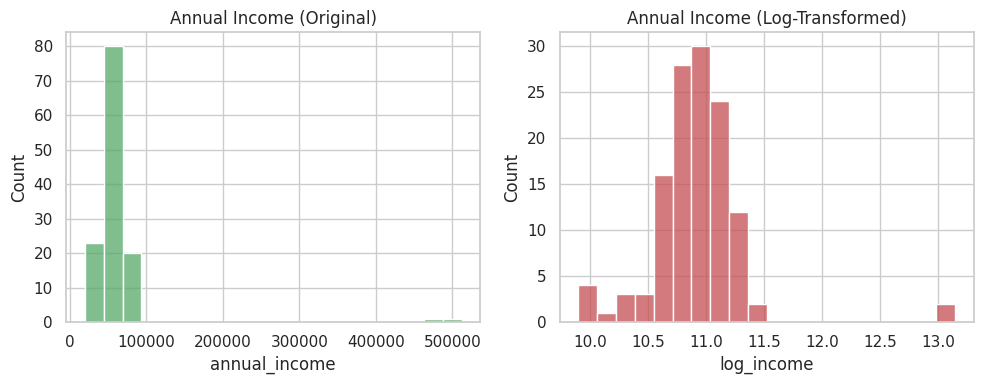

In [32]:
# Remove the implausible age (clear data error)
implausible_age = df_clean["age"] < 15
df_final = df_clean[~implausible_age].copy()
print(f"Removed {implausible_age.sum()} row(s) with implausible age")

# Log-transform income instead of removing the high-but-plausible earners
df_final["log_income"] = np.log1p(df_final["annual_income"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df_final["annual_income"], bins=20, ax=axes[0], color="#55A868")
axes[0].set_title("Annual Income (Original)")
sns.histplot(df_final["log_income"], bins=20, ax=axes[1], color="#C44E52")
axes[1].set_title("Annual Income (Log-Transformed)")
plt.tight_layout()
plt.show()

## 8. Wrap-Up
**TODO:** In a markdown cell below, summarize:
1. How many rows/columns you started with vs. ended with
2. Which missing-data policy you used per column, and why
3. Which outliers you kept vs. removed vs. transformed, and why
4. One thing that surprised you while exploring this dataset

In [ ]:
# TODO: final summary print, e.g.
# print(f"Started with {df.shape[0]} rows, ended with {df_final.shape[0]} rows")

<details>

```python
print(f"Started with {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Ended with {df_final.shape[0]} rows, {df_final.shape[1]} columns")
print()
print("Missing-data policies: country -> 'Unknown' mask, age -> median impute, "
      "annual_income -> median impute, satisfaction_score -> mode impute")
print()
print("Outliers: removed 1 implausible age (<15); kept high incomes but added a "
      "log-transformed version to reduce their influence in later modeling")
```

</details>

In [33]:
print(f"Started with {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Ended with {df_final.shape[0]} rows, {df_final.shape[1]} columns")
print()
print("Missing-data policies: country -> 'Unknown' mask, age -> median impute, "
      "annual_income -> median impute, satisfaction_score -> mode impute")
print()
print("Outliers: removed 1 implausible age (<15); kept high incomes but added a "
      "log-transformed version to reduce their influence in later modeling")

Started with 126 rows, 8 columns
Ended with 125 rows, 9 columns

Missing-data policies: country -> 'Unknown' mask, age -> median impute, annual_income -> median impute, satisfaction_score -> mode impute

Outliers: removed 1 implausible age (<15); kept high incomes but added a log-transformed version to reduce their influence in later modeling


**Summary (example):**
1. Started with 126 rows / 8 columns, ended with 119 rows / 9 columns (after removing duplicates and the implausible age, and adding `log_income`).
2. Missing values were masked (`country`) or imputed with median/mode depending on whether the column was categorical, skewed numeric, or ordinal.
3. The implausible age was removed as a clear data error; the high incomes were kept but log-transformed rather than deleted, since they were plausible and potentially informative.
4. What stood out: the same fix doesn't work for every outlier - deciding "error vs. real" mattered more than applying one rule to every extreme value.


------------------------------------------

| <img src="https://github.com/madhawapolkotuwa.png" width="80" style="border-radius: 50%;"> | **MPCoding**<br>*Machine Learning Tutorial Series*<br><br> [![YouTube](https://img.shields.io/badge/YouTube-%23FF0000.svg?style=for-the-badge&logo=YouTube&logoColor=white)](https://www.youtube.com/@MP-Coding) [![GitHub](https://img.shields.io/badge/github-repo-blue?logo=github)](https://github.com/madhawapolkotuwa) |
|---|---|

<p align="left" style="font-size: 0.85em; color: gray; margin-top: 10px;">
  © 2026 MPCoding. Educational materials are free to use with proper attribution.
</p>